---
title: "Chapter 20 demo: Customer retention with survival analysis"
sidebar: demos
---

# Lecture 20: Survival analysis

Which customers leave earlier, and how could we use that information to prioritize retention efforts?

We will inspect and clean customer data, estimate Kaplan–Meier survival curves, and interpret a Cox proportional hazards model using **lifelines**. We assume right censoring has already been covered in the slides.

**Class route:** Sections 1–4 are the core demo. Section 5 adds predicted curves if time permits; the remaining sections are optional exploration. There is no associated homework assignment.

## Setup

Run cells in order from the directory containing this notebook. Download the [Telco Customer Churn dataset](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) and place `WA_Fn-UseC_-Telco-Customer-Churn.csv` in the adjacent `data/` folder.

Install `lifelines` in the notebook's Python environment if needed: `uv add lifelines`. Other dependencies are pandas, NumPy, Matplotlib, and scikit-learn.

In [1]:
#| code-fold: true
#| code-summary: "Show imports and setup"
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.plotting import add_at_risk_counts
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder

plt.rcParams["font.size"] = 12
DATA_PATH = Path("data") / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
RANDOM_STATE = 123

## 1. Inspect and clean the data

One row represents a customer. `tenure` is their observed time with the service, in months. `Churn = Yes` indicates an observed departure; `No` indicates right censoring at the snapshot.

We reserve a test set for optional evaluation. All exploratory curves and model fitting below use the training set.

In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Download the Telco CSV and place it at {DATA_PATH.resolve()}")
raw = pd.read_csv(DATA_PATH)
train_raw, test_raw = train_test_split(
    raw, test_size=0.25, random_state=RANDOM_STATE, stratify=raw["Churn"]
)
display(train_raw.head())
train_raw.info()
display(train_raw.isna().sum().rename("missing values"))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
1487,5035-PGZXH,Female,0,No,No,56,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Electronic check,106.80,5914.4,No
1485,9809-IMGCQ,Male,1,No,No,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,96.70,2082.95,Yes
4731,8748-HFWBO,Male,0,Yes,Yes,19,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,19.90,357.7,No
5987,1099-GODLO,Female,0,Yes,Yes,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.35,20.35,No
5058,1376-HHBDV,Female,0,No,No,30,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,48.80,1536.75,No


<class 'pandas.core.frame.DataFrame'>
Index: 5282 entries, 1487 to 5298
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5282 non-null   object 
 1   gender            5282 non-null   object 
 2   SeniorCitizen     5282 non-null   int64  
 3   Partner           5282 non-null   object 
 4   Dependents        5282 non-null   object 
 5   tenure            5282 non-null   int64  
 6   PhoneService      5282 non-null   object 
 7   MultipleLines     5282 non-null   object 
 8   InternetService   5282 non-null   object 
 9   OnlineSecurity    5282 non-null   object 
 10  OnlineBackup      5282 non-null   object 
 11  DeviceProtection  5282 non-null   object 
 12  TechSupport       5282 non-null   object 
 13  StreamingTV       5282 non-null   object 
 14  StreamingMovies   5282 non-null   object 
 15  Contract          5282 non-null   object 
 16  PaperlessBilling  5282 non-null   object 
 1

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
Name: missing values, dtype: int64

**Predict:** Does zero missing values mean every column is ready for modeling? Why is `TotalCharges` stored as text?

In [3]:
# Catch the conversion error so running the whole notebook remains possible.
try:
    train_raw["TotalCharges"].astype(float)
except ValueError as error:
    print(error)

# Ordinary printing can hide a blank string; repr makes whitespace visible.
charges_text = train_raw["TotalCharges"].astype("string")
blank_charges = charges_text.str.strip().eq("")
display(charges_text.loc[blank_charges].map(repr).rename("visible representation"))
display(train_raw.loc[blank_charges, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

could not convert string to float: ' '


1082    ' '
6754    ' '
1340    ' '
5218    ' '
488     ' '
4380    ' '
6670    ' '
753     ' '
Name: visible representation, dtype: object

,tenure,MonthlyCharges,TotalCharges,Churn
1082,0,25.75,,No
6754,0,61.90,,No
1340,0,56.05,,No
5218,0,19.70,,No
488,0,52.55,,No
4380,0,20.00,,No
6670,0,73.35,,No
753,0,20.25,,No


<details>
<summary>Reveal explanation</summary>

Whitespace is a string value, so `isna()` does not count it as missing. Inspect the affected rows before deciding what missing means: do they have zero tenure, suggesting no accumulated bill yet? That is a hypothesis to check, rather than a reason to blindly replace every missing charge with zero.

</details>

Next, we clean `TotalCharges` and create an **`event` column** for `lifelines`:

- **1 = churn was observed** (`Churn = Yes`). The recorded tenure ends with the customer leaving.
- **0 = churn was not observed** (`Churn = No`). We know the customer stayed for their recorded tenure, but do not know when they will eventually leave.

This is the numeric event indicator expected by `event_observed` in Kaplan–Meier and `event_col` in the Cox model. The package also accepts boolean values; 0 and 1 make the mapping easy to inspect. Crucially, **0 does not mean “this customer will never churn.”**


In [4]:
def clean_customers(frame):
    cleaned = frame.copy()
    # Strip whitespace, mark empty strings as missing, then require numeric values.
    charges = cleaned["TotalCharges"].astype("string").str.strip().replace("", pd.NA)
    cleaned["TotalCharges"] = pd.to_numeric(charges, errors="raise")
    # lifelines needs to know whether the event was observed (1) or censored (0).
    cleaned["event"] = cleaned["Churn"].map({"Yes": 1, "No": 0})
    assert cleaned["event"].notna().all(), "Unexpected Churn label"
    assert cleaned["tenure"].notna().all() and cleaned["tenure"].ge(0).all()
    return cleaned

train = clean_customers(train_raw)
test = clean_customers(test_raw)
display(train[["TotalCharges", "tenure", "event"]].dtypes)
display(train["TotalCharges"].isna().value_counts().rename("customers"))

TotalCharges    Float64
tenure            int64
event             int64
dtype: object

TotalCharges
False    5274
True        8
Name: customers, dtype: int64

After all this preprocessing, **we are going to exclude `TotalCharges` from our survival model!** Why?

We want to model time **from joining to churn**, but `TotalCharges` grows as a customer stays. The recorded total is from the end of their observed time, not from signup. It therefore contains information accumulated during the very period we are trying to model. A large total may simply tell us that the customer has already stayed a long time.

Cleaning the column was still useful: it showed us how whitespace can hide missing values. But a clean column is not automatically a suitable predictor. Since we exclude `TotalCharges`, we do not need to fill its missing values for this model.

We also exclude `customerID`. We keep `tenure` and `event` to tell `lifelines` how long each customer was observed and whether they churned; these are not predictors.

**Discuss:** Could `TotalCharges` ever be useful for predicting churn?

<details>
<summary>Reveal explanation</summary>

Yes. At a defined prediction time, such as month 12, charges accumulated **up to month 12** could help predict subsequent churn among customers still active then. That is a different task, requiring data available at that time and an appropriate follow-up design. With a billing history, we could also consider a model that allows customer features to change over time.

Contract, internet service, and monthly charges are also recorded at the snapshot. For this teaching example we treat them as fixed characteristics. Before using this model in practice, we would need to check whether these features changed and obtain their earlier values where needed.

</details>

In [5]:
train

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,event
1487,5035-PGZXH,Female,0,No,No,56,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,One year,Yes,Electronic check,106.80,5914.4,No,0
1485,9809-IMGCQ,Male,1,No,No,22,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,Month-to-month,Yes,Electronic check,96.70,2082.95,Yes,1
4731,8748-HFWBO,Male,0,Yes,Yes,19,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,One year,No,Mailed check,19.90,357.7,No,0
5987,1099-GODLO,Female,0,Yes,Yes,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.35,20.35,No,0
5058,1376-HHBDV,Female,0,No,No,30,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,48.80,1536.75,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2873,0148-DCDOS,Male,0,No,No,25,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),94.70,2362.1,Yes,1
4935,4584-LBNMK,Male,1,Yes,No,45,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,One year,No,Credit card (automatic),24.70,1174.35,No,0
6883,2133-TSRRM,Female,0,No,Yes,34,Yes,No,Fiber optic,Yes,...,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),105.35,3688.6,No,0
6395,3058-HJCUY,Male,0,Yes,Yes,41,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,One year,Yes,Electronic check,102.60,4213.35,Yes,1


## 2. Estimate overall retention with Kaplan–Meier

Kaplan–Meier uses only observed durations and event indicators. It needs neither one-hot encoding nor scaling. Here, survival means remaining with the service. At any month on the horizontal axis, the curve estimates the probability that a customer stays beyond that month.

**Predict:** How does a censored customer contribute before their observation ends?

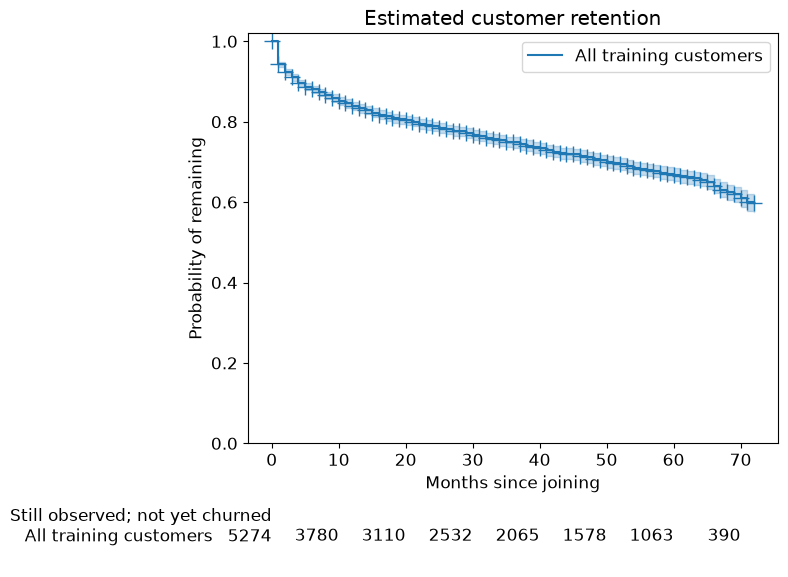

12    0.839878
24    0.788243
Name: estimated survival, dtype: float64

In [6]:
km_all = KaplanMeierFitter(label="All training customers")
km_all.fit(train["tenure"], event_observed=train["event"])
fig, ax = plt.subplots(figsize=(8, 6))
km_all.plot_survival_function(ax=ax, show_censors=True)
ax.set(title="Estimated customer retention", xlabel="Months since joining",
       ylabel="Probability of remaining", ylim=(0, 1.02))
add_at_risk_counts(km_all, ax=ax, rows_to_show=["At risk"])
# Replace the package’s statistical label with a plain-language description.
count_ax = fig.axes[-1]
count_ax.set_xticklabels([
    label.get_text().replace("At risk", "Still observed; not yet churned")
    for label in count_ax.get_xticklabels()
])
plt.tight_layout()
plt.show()
display(km_all.survival_function_at_times([12, 24]).rename("estimated survival"))

**Discuss:** How would you explain the curve’s value at 12 months to a retention team? Where would you consider testing an onboarding or retention intervention? Why should we be cautious about the right-hand tail?

<details>
<summary>Reveal explanation</summary>

The curve’s value at 12 months estimates the probability of remaining beyond 12 months under the assumptions of this analysis. A customer who has not churned is counted among the customers still being observed until their recorded tenure ends. Their observation ending is not counted as a departure.

A steep early decline can motivate testing earlier outreach. The shaded band shows uncertainty around the estimated curve: a wider band means a less precise estimate. Near the right-hand end, fewer customers are still being observed, so avoid drawing strong conclusions from small differences. The row labeled “Still observed; not yet churned” counts customers whose observations have not ended and who have not yet left. The package calls these customers “at risk” because they could still churn—not because their predicted survival probability falls below a threshold. A customer whose observation ended at month 8 is no longer counted at month 12, even if they had not churned.

We assume that customers whose observations end would have similar future retention to those still observed. If observations end because customers are about to leave, this assumption would be questionable. The curve helps us decide when to test outreach; it does not show whether outreach will work.

</details>

## 3. Compare contract types

**Predict:** Which contract group will have the highest retention? Will that difference necessarily be caused by the contract?

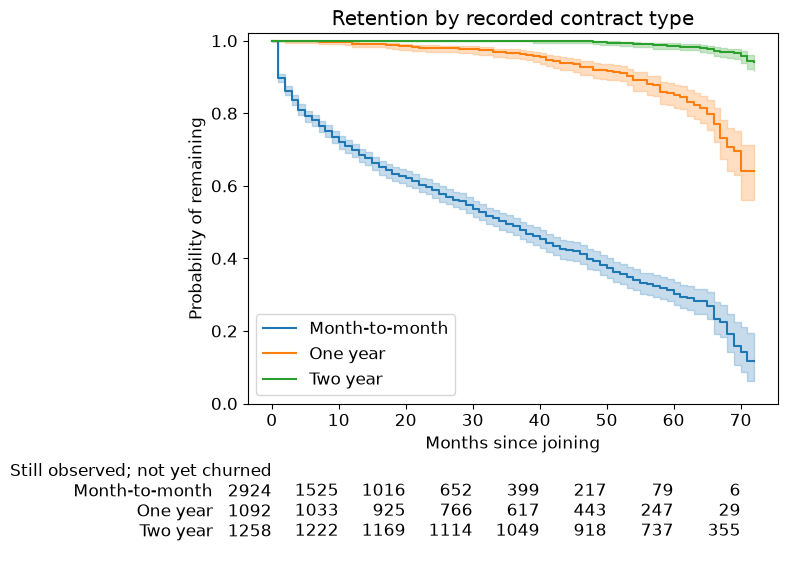

,Customers,Observed churns,12-month retention,24-month retention
Contract,,,,
Month-to-month,2924,1251,0.699,0.588
One year,1093,117,0.991,0.980
Two year,1265,34,1.000,1.000


In [7]:
contract_order = ["Month-to-month", "One year", "Two year"]
fig, ax = plt.subplots(figsize=(8, 6))
contract_fitters = []
contract_summary = []
for contract in contract_order:
    group = train.loc[train["Contract"].eq(contract)]
    km = KaplanMeierFitter(label=contract)
    km.fit(group["tenure"], event_observed=group["event"])
    km.plot_survival_function(ax=ax)
    contract_fitters.append(km)
    contract_summary.append({
        "Contract": contract, "Customers": len(group), "Observed churns": group["event"].sum(),
        "12-month retention": km.predict(12), "24-month retention": km.predict(24),
    })
ax.set(title="Retention by recorded contract type", xlabel="Months since joining",
       ylabel="Probability of remaining", ylim=(0, 1.02))
add_at_risk_counts(*contract_fitters, ax=ax, rows_to_show=["At risk"])
# Replace the package’s statistical label with a plain-language description.
count_ax = fig.axes[-1]
count_ax.set_xticklabels([
    label.get_text().replace("At risk", "Still observed; not yet churned")
    for label in count_ax.get_xticklabels()
])
plt.tight_layout()
plt.show()
display(pd.DataFrame(contract_summary).set_index("Contract").round(3))

**Discuss:** Would these curves justify moving everyone to a two-year contract? What else might differ between these customers?

<details>
<summary>Reveal explanation</summary>

Customers select contracts and may differ in price, service needs, satisfaction, or other characteristics. Contract changes during follow-up are also unobserved. These curves compare the groups as they are; they do not separate contract type from the other ways the customers differ. They do not tell us what would happen if we changed someone's contract.

A possible next step is to test a voluntary contract offer with a randomized retention experiment, measuring both retention and business costs. The curves help identify a hypothesis and audience for that test.

</details>

## 4. Adjust for several features with a Cox model

Can we examine these associations together? `CoxPHFitter` lets us relate several customer characteristics to time to churn while accounting for censoring. We will focus on fitting the model, reading its summary table, and interpreting its plots.

For the main demo, focus on the **sign of each coefficient**: positive values are associated with faster churn, and negative values with slower churn, holding the other included features fixed. We will use predicted survival curves to understand the differences in retention probabilities.

We use a compact set of predictors: contract, internet service, monthly charges, and senior-citizen status. Monthly charges are divided by 10, so one unit means **$10/month**. We choose a comparison group for each categorical feature so the results are easier to read. We reuse our familiar `ColumnTransformer`: rescale monthly charges, one-hot encode categorical features, and pass through `SeniorCitizen`. `drop="first"` leaves one comparison group out of each categorical encoding.

Fit the preprocessor on training predictors only, then use `transform` for the test set and new customers. Keep `tenure` and `event` outside the predictor preprocessor. After transforming, append these two outcome columns so `lifelines` knows how long each customer was observed and whether churn occurred. Unlike a classifier with one target, this estimator needs both pieces of outcome information.

The comparison groups are **one-year contracts** and **DSL**. We put these categories first in the encoder and use `drop="first"`. This gives us explicit month-to-month and two-year coefficients, each compared with a one-year contract. The omitted one-year category is still represented: both contract indicators are 0 for those customers. We use a small L2 penalty (regularization, as in ridge regression) to keep coefficients from becoming too large. We still need to check whether the model is a reasonable fit.

In [8]:
numeric_features = ["MonthlyCharges"]
categorical_features = ["Contract", "InternetService"]
passthrough_features = ["SeniorCitizen"]
raw_predictor_columns = numeric_features + categorical_features + passthrough_features

# A $10 increase becomes a one-unit increase; retain an informative column name.
def dollars_to_tens(values):
    return values / 10


def charge_feature_names(transformer, input_features):
    return ["MonthlyCharges10"]


preprocessor = ColumnTransformer(
    transformers=[
        ("charges", FunctionTransformer(
            dollars_to_tens, feature_names_out=charge_feature_names
        ), numeric_features),
        ("categorical", OneHotEncoder(
            categories=[["One year", "Month-to-month", "Two year"], ["DSL", "Fiber optic", "No"]],
            drop="first", sparse_output=False,
        ), categorical_features),
        ("passthrough", "passthrough", passthrough_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_train = preprocessor.fit_transform(train[raw_predictor_columns])
X_test = preprocessor.transform(test[raw_predictor_columns])
predictor_columns = X_train.columns.tolist()
display(X_train.head())

,MonthlyCharges10,Contract_Month-to-month,Contract_Two year,InternetService_Fiber optic,InternetService_No,SeniorCitizen
1487,10.680,0.0,0.0,1.0,0.0,0
1485,9.670,1.0,0.0,1.0,0.0,1
4731,1.990,0.0,0.0,0.0,1.0,0
5987,2.035,0.0,1.0,0.0,1.0,0
5058,4.880,1.0,0.0,0.0,0.0,0


In [9]:
# Outcomes bypass preprocessing; preserving row indices keeps them aligned.
train_surv = X_train.join(train[["tenure", "event"]])
test_surv = X_test.join(test[["tenure", "event"]])
assert not train_surv.isna().any().any(), "Inspect missing model inputs before fitting"
cph = CoxPHFitter(penalizer=0.01, l1_ratio=0.0)
cph.fit(train_surv, duration_col="tenure", event_col="event")
coefficients = cph.params_.sort_values(ascending=False).rename("Coefficient")
display(coefficients.to_frame().round(3))

,Coefficient
covariate,
Contract_Month-to-month,1.903
InternetService_Fiber optic,1.186
SeniorCitizen,-0.002
MonthlyCharges10,-0.227
InternetService_No,-0.975
Contract_Two year,-1.510


### Read the coefficients

- **Positive:** associated with faster churn, holding the other included features fixed.
- **Negative:** associated with slower churn, holding the other included features fixed.
- For a categorical feature, compare with its omitted group: **one-year contracts** or **DSL**. For monthly charges, one unit means a **$10/month increase**.
- The table is sorted from the most positive to the most negative coefficient. This makes the directions easier to scan; it is not a feature-importance ranking because the features have different units and comparison groups.
- In the plot, each dot is an estimated coefficient. The horizontal line shows uncertainty: a longer line means a less precise estimate. The vertical line at **0** means no difference according to the model. If a horizontal line crosses 0, avoid claiming a clear direction from this result alone.

Coefficient values are not changes in churn probability or months of service. For a practical comparison, read the predicted retention curves next.

**Discuss:** Which features are associated with faster or slower churn? Why might these results tell a different story from the separate group curves?

<details>
<summary>Reveal explanation</summary>

The separate group curves mix together differences in contract, price, and other customer features. The Cox model considers several features together, so its comparisons can look different. Features we have not included and changes during a customer’s time with the service can still affect the results. The coefficients do not tell us what would happen if we changed a customer’s plan. Regularization also pulls estimates toward zero.

To answer “What proportion of customers might stay beyond 12 months?”, use the predicted survival curve rather than interpreting a coefficient as a probability.

</details>

<details>
<summary>Optional: what is the hazard ratio in the lifelines summary?</summary>

The full `cph.summary` table also includes `exp(coef)`, called a **hazard ratio**. It compares how quickly customers leave at a given point in time, among those who have stayed until then, while holding the other included features fixed.

A value above 1 corresponds to a positive coefficient; below 1 corresponds to a negative coefficient. A value of 1 means the same churn hazard as the comparison group. For example, 1.5 means 50% higher churn hazard—not a 50-percentage-point increase in churn probability or 50% shorter lifetime.

This is optional detail; coefficient signs and predicted survival curves are enough for our main walkthrough.

</details>

## 5. Compare predicted survival curves (if time permits)

Use one observed training customer as a reference profile, then vary the contract while retaining their other features. These are model-based comparisons, not estimates of what would happen if we changed that customer's contract.

,MonthlyCharges,Contract,InternetService,SeniorCitizen
Contract scenario,,,,
Month-to-month,106.8,Month-to-month,Fiber optic,0
One year,106.8,One year,Fiber optic,0
Two year,106.8,Two year,Fiber optic,0


,MonthlyCharges10,Contract_Month-to-month,Contract_Two year,InternetService_Fiber optic,InternetService_No,SeniorCitizen
Contract scenario,,,,,,
Month-to-month,10.68,1.0,0.0,1.0,0.0,0
One year,10.68,0.0,0.0,1.0,0.0,0
Two year,10.68,0.0,1.0,1.0,0.0,0


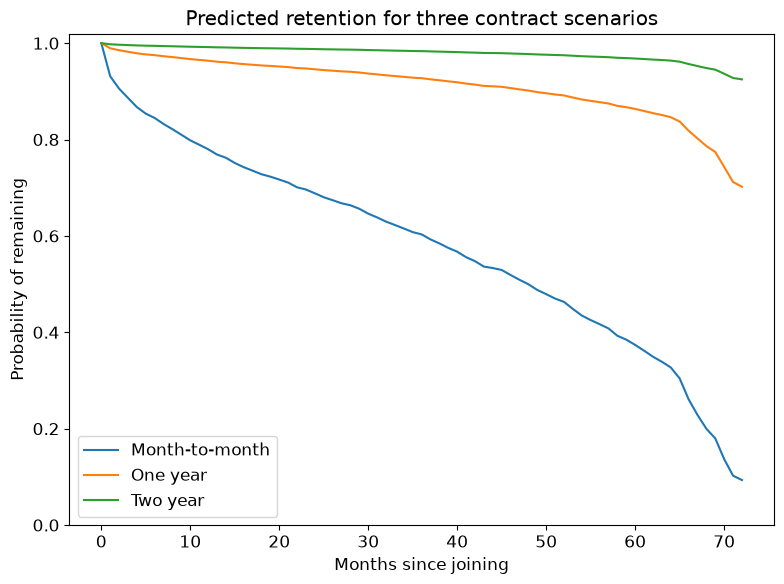

,12-month retention,24-month retention
Month-to-month,0.780,0.688
One year,0.964,0.946
Two year,0.992,0.988


In [10]:
raw_profiles = pd.concat([train[raw_predictor_columns].iloc[[0]]] * 3, ignore_index=True)
raw_profiles["Contract"] = contract_order
raw_profiles.index = pd.Index(contract_order, name="Contract scenario")
display(raw_profiles)
# Reuse the training-fitted preprocessor; do not fit on these new profiles.
profiles = preprocessor.transform(raw_profiles)
profiles.index = pd.Index(contract_order, name="Contract scenario")
display(profiles)
curves = cph.predict_survival_function(profiles)
ax = curves.plot(figsize=(8, 6))
ax.set(title="Predicted retention for three contract scenarios", xlabel="Months since joining",
       ylabel="Probability of remaining", ylim=(0, 1.02))
plt.tight_layout()
plt.show()
display(cph.predict_survival_function(profiles, times=[12, 24]).T.rename(columns={12: "12-month retention", 24: "24-month retention"}).round(3))

**Discuss:** With a limited retention budget, is predicted churn risk sufficient to decide whom to contact?

<details>
<summary>Reveal explanation</summary>

We also need intervention effectiveness, contact costs, customer value, and the consequences of contacting different customers. A high-risk customer is not necessarily someone whose behavior the intervention can change. Test the proposed action rather than treating risk as treatment benefit.

</details>

## Main-demo takeaways

1. Whitespace can hide missing values; inspect representations and types.
2. A cleaned feature can still be inappropriate: `TotalCharges` accumulates during the duration being modeled.
3. Kaplan–Meier describes retention while accounting for right censoring; subgroup curves suggest hypotheses.
4. Cox coefficient signs indicate faster or slower churn while accounting for the other included features. Use survival curves for retention probabilities, and experiments to test whether an action improves retention.

**Stop here for the short class demo.** The sections below are optional.

## Optional A. Compare online security among internet customers

Exclude customers without internet: “no internet service” is not the same comparison as declining online security. This comparison does not account for other differences between the groups and is not included in the compact Cox model.

**Predict:** Would an association justify selling online security as a churn-prevention intervention?

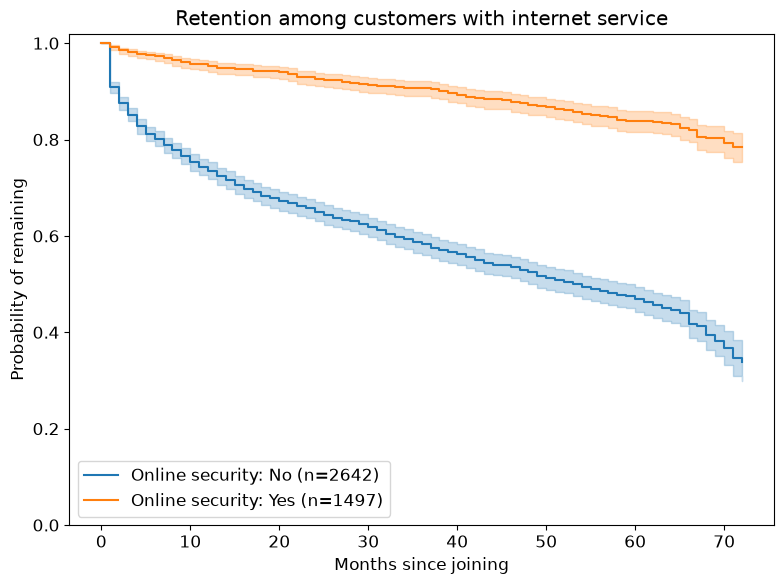

,Customers,12-month retention,24-month retention
Online security,,,
No,2642,0.735,0.651
Yes,1497,0.953,0.926


In [11]:
internet = train.loc[train["InternetService"].isin(["DSL", "Fiber optic"])]
fig, ax = plt.subplots(figsize=(8, 6))
security_summary = []
for security in ["No", "Yes"]:
    group = internet.loc[internet["OnlineSecurity"].eq(security)]
    km = KaplanMeierFitter(label=f"Online security: {security} (n={len(group)})")
    km.fit(group["tenure"], event_observed=group["event"])
    km.plot_survival_function(ax=ax)
    security_summary.append({"Online security": security, "Customers": len(group),
                             "12-month retention": km.predict(12), "24-month retention": km.predict(24)})
ax.set(title="Retention among customers with internet service", xlabel="Months since joining",
       ylabel="Probability of remaining", ylim=(0, 1.02))
plt.tight_layout()
plt.show()
display(pd.DataFrame(security_summary).set_index("Online security").round(3))

<details>
<summary>Reveal explanation</summary>

Service bundles, customer preferences, internet type, and contract may differ between groups. Treat the result as a hypothesis for further investigation or an experiment; the curve does not measure the causal benefit of adding online security.

</details>

## Optional B. Predict remaining retention for an active customer

The earlier curves start at signup. For an active customer, we can instead ask: **“Given that this customer has already stayed this long, how likely are they to remain for another 12 months?”**

Pass their observed tenure to `conditional_after` to account for how long they have already stayed; the resulting time axis is months into the future. Restrict the horizon to available follow-up rather than extrapolating an unsupported lifetime.

Customer has already remained for 56 months.


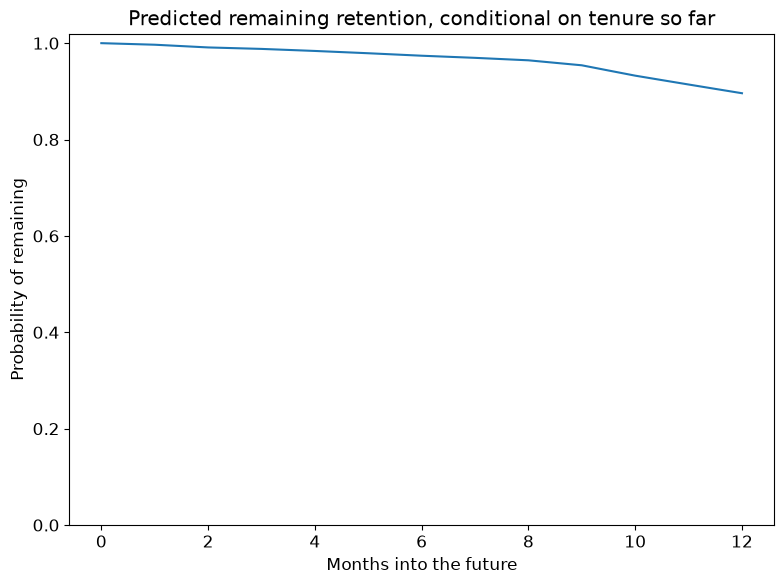

In [13]:
active = train_surv.loc[train_surv["event"].eq(0)].iloc[[0]]
current_tenure = float(active["tenure"].iloc[0])
remaining_horizon = min(12, float(train_surv["tenure"].max()) - current_tenure)
print(f"Customer has already remained for {current_tenure:g} months.")
if remaining_horizon > 0:
    future_times = np.linspace(0, remaining_horizon, 25)
    conditional = cph.predict_survival_function(
        active[predictor_columns], times=future_times, conditional_after=[current_tenure]
    )
    ax = conditional.plot(figsize=(8, 6), legend=False)
    ax.set(title="Predicted remaining retention, conditional on tenure so far",
           xlabel="Months into the future", ylabel="Probability of remaining", ylim=(0, 1.02))
    plt.tight_layout()
    plt.show()
else:
    print("No additional follow-up horizon is supported for this customer.")

## Optional C. Evaluate ranking on the reserved test set

The **concordance index** asks whether the model tends to assign higher churn risk to customers who leave sooner. It accounts for the fact that we do not know the eventual departure time of censored customers, and only uses pairs whose order can be determined.

A score around 0.5 means chance-level ranking; 1 means all the compared pairs are ranked correctly. A good ranking does not guarantee accurate retention probabilities or tell us whether an intervention will work.

Use this test set once after settling the model. If its results guide further changes, reserve new data for final evaluation.

In [14]:
print(f"Training concordance: {cph.concordance_index_:.3f}")
print(f"Test concordance: {cph.score(test_surv, scoring_method='concordance_index'):.3f}")

Training concordance: 0.828
Test concordance: 0.817


## References

- [Telco Customer Churn dataset](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
- [Kaplan–Meier estimation in lifelines](https://lifelines.readthedocs.io/en/latest/fitters/univariate/KaplanMeierFitter.html)
- [Survival regression in lifelines](https://lifelines.readthedocs.io/en/latest/Survival%20Regression.html)
- [Cox model API, prediction, and penalties](https://lifelines.readthedocs.io/en/latest/fitters/regression/CoxPHFitter.html)